# Entendendo a base

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_excel(r'class.xlsx')
df.head()


,review_text_processed,Classificacao
0,"produto excelente. por tudo que vi, sei que pe...",positivo
1,"esta e um tv lcd com muita qualidade, possui u...",positivo
2,um otimo aparelho para aquecer um comodo. aque...,positivo
3,"jogo muito bom, graficos realistas e som muito...",positivo
4,"confesso que nao conhecia a marca midea, por e...",positivo


In [ ]:
df['Classificacao'].value_counts()

,count
Classificacao,
positivo,85
negativo,15


# Abordagem clássica (supervisionada)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.downloader import download
download('stopwords')
from nltk.corpus import stopwords

# Definindo as stopwords em português
stop_words_portuguese = list(stopwords.words('portuguese'))

# Criação do vetor TF-IDF
Tfidf = TfidfVectorizer(ngram_range=(1, 4),
                      stop_words=stop_words_portuguese, #Já remove as stopwords
                      strip_accents = 'unicode', #Já remove os acentos do texto
                      max_features=1024, #Pega as n palavras mais frequentes e corta o número de features
                      norm = 'l1'
                      #l1 soma do vetor de cada frase é 1;
                      #l2 soma do quadrado dos elementos do vetor é 1; None sem normalizar
                        )
# Corpus
corpus = df['review_text_processed'].values

# Transformação das corpus em matriz TF-IDF
Tfidf_X = Tfidf.fit_transform(corpus)

# Conversão para array
outpt = Tfidf_X.toarray()

# Salvar no dataframe

df['vetores_tfidf'] = list(outpt)
df.head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['ate', 'eramos', 'estao', 'estavamos', 'estiveramos', 'estivessemos', 'foramos', 'fossemos', 'ha', 'hao', 'houveramos', 'houverao', 'houveriamos', 'houvessemos', 'ja', 'nao', 'sao', 'sera', 'serao', 'seriamos', 'so', 'tambem', 'tera', 'terao', 'teriamos', 'tinhamos', 'tiveramos', 'tivessemos', 'voce', 'voces'] not in stop_words.
  warnings.warn(


,review_text_processed,Classificacao,vetores_tfidf
0,"produto excelente. por tudo que vi, sei que pe...",positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,"esta e um tv lcd com muita qualidade, possui u...",positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2,um otimo aparelho para aquecer um comodo. aque...,positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
3,"jogo muito bom, graficos realistas e som muito...",positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
4,"confesso que nao conhecia a marca midea, por e...",positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


In [ ]:
# Criar um modelo de classificação supervisionado com base na coluna target
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import numpy as np

# Preparar dados - Converter para numpy array 2D
X = np.array(df['vetores_tfidf'].tolist())
y = df['Classificacao'].values

# Label Encoder para converter labels em números
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split treino/teste
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

# Treinar modelo de Regressão Logística
print("Treinando modelo de Regressão Logística...")
model_lr = LogisticRegression(max_iter=1000,
                              solver = 'saga',
                              penalty = 'elasticnet',
                              l1_ratio = 0.2,
                              random_state=42,
                              n_jobs=-1,
                              class_weight='balanced')
model_lr.fit(X_train, y_train)

# Predições
y_train_pred = model_lr.predict(X_train)
y_test_pred = model_lr.predict(X_test)

# Scores
train_score = model_lr.score(X_train, y_train)
test_score = model_lr.score(X_test, y_test)

# Classification Report para Treino
print("\n" + "="*60)
print("CLASSIFICATION REPORT - TREINO")
print("="*60)
print(classification_report(y_train, y_train_pred, target_names=le.classes_))

# Classification Report para Teste
print("\n" + "="*60)
print("CLASSIFICATION REPORT - TESTE")
print("="*60)
print(classification_report(y_test, y_test_pred, target_names=le.classes_))

Treinando modelo de Regressão Logística...

CLASSIFICATION REPORT - TREINO
              precision    recall  f1-score   support

    negativo       0.50      0.08      0.14        12
    positivo       0.86      0.99      0.92        68

    accuracy                           0.85        80
   macro avg       0.68      0.53      0.53        80
weighted avg       0.81      0.85      0.80        80


CLASSIFICATION REPORT - TESTE
              precision    recall  f1-score   support

    negativo       0.00      0.00      0.00         3
    positivo       0.85      1.00      0.92        17

    accuracy                           0.85        20
   macro avg       0.42      0.50      0.46        20
weighted avg       0.72      0.85      0.78        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import time

In [ ]:
inicio = time.time()
df['classico'] = le.inverse_transform(model_lr.predict(X))
fim = time.time()
print(fim - inicio)
df.head()

0.0047664642333984375


,review_text_processed,Classificacao,vetores_tfidf,classico
0,"produto excelente. por tudo que vi, sei que pe...",positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",positivo
1,"esta e um tv lcd com muita qualidade, possui u...",positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",positivo
2,um otimo aparelho para aquecer um comodo. aque...,positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",positivo
3,"jogo muito bom, graficos realistas e som muito...",positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",positivo
4,"confesso que nao conhecia a marca midea, por e...",positivo,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",positivo


In [ ]:
print(classification_report(df['Classificacao'], df['classico']))

              precision    recall  f1-score   support

    negativo       0.50      0.07      0.12        15
    positivo       0.86      0.99      0.92        85

    accuracy                           0.85       100
   macro avg       0.68      0.53      0.52       100
weighted avg       0.80      0.85      0.80       100



# Jev

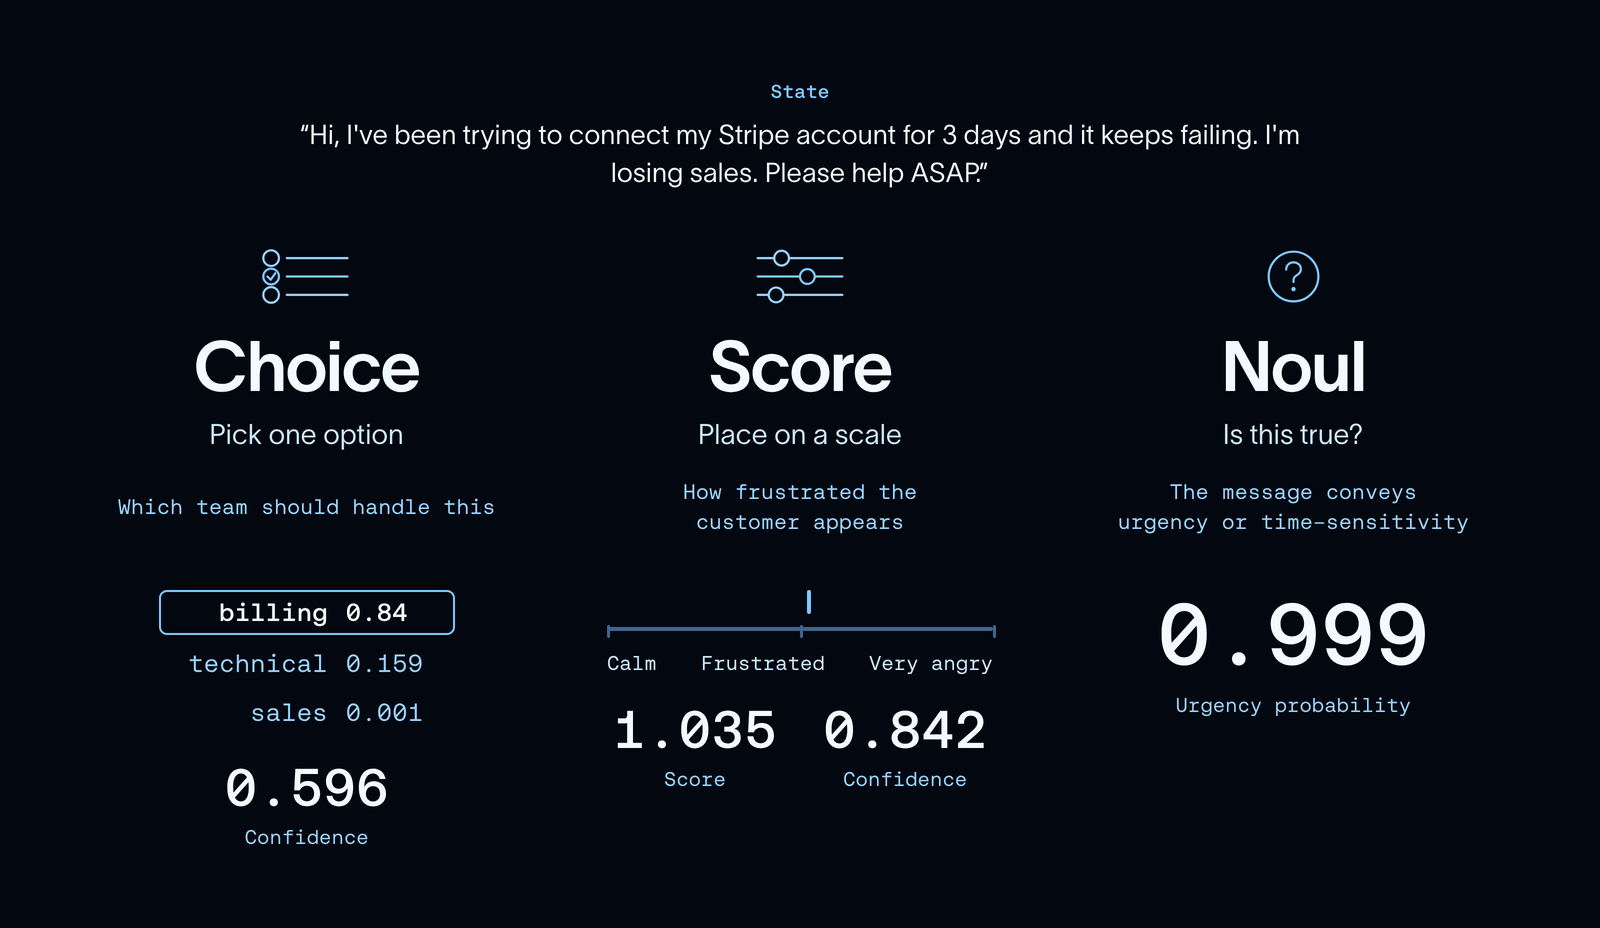

In [ ]:
import requests
import json
from google.colab import userdata

def jev(state):
  response = requests.post(
    url="https://openrouter.ai/api/alpha/decisions",
    headers={
      "Authorization": f"Bearer {userdata.get('OPENROUTER_API_KEY')}",
      "Content-Type": "application/json"
    },
    data=json.dumps({
      "model": "~typesafe/jev-latest",
      "state": state,
      "questions": {
        "sentimento": {
          "type": "choice",
          "instructions": "Qual o sentimento do texto?",
          "criteria": {
            "positivo": "sentido positivo",
            "negativo": "sentimento negativo"
        }
        }
      }
    })
  )
  return response.json()["answers"]

In [ ]:
inicio = time.time()
resultados = []
for i in range(len(df)):
  resultados.append(jev(df['review_text_processed'].values[i])['sentimento']['choice'])
fim = time.time()
print(fim - inicio)
df['jev'] = resultados

142.06954979896545


In [ ]:
print(classification_report(df['Classificacao'], df['jev']))

              precision    recall  f1-score   support

    negativo       0.73      0.73      0.73        15
    positivo       0.95      0.95      0.95        85

    accuracy                           0.92       100
   macro avg       0.84      0.84      0.84       100
weighted avg       0.92      0.92      0.92       100



# OpenAI Decisions

In [ ]:
import requests
import json
from google.colab import userdata

def OADecisions(state):
  response = requests.post(
    url="https://openrouter.ai/api/alpha/decisions",
    headers={
      "Authorization": f"Bearer {userdata.get('OPENROUTER_API_KEY')}",
      "Content-Type": "application/json"
    },
    data=json.dumps({
      "model": "openai/gpt-6-luna-decisions",
      "state": state,
      "questions": {
        "sentimento": {
          "type": "choice",
          "instructions": "Qual o sentimento do texto?",
          "criteria": {
            "positivo": "sentido positivo",
            "negativo": "sentimento negativo"
        }
        }
      }
    })
  )
  return response.json()["answers"]

In [ ]:
inicio = time.time()
resultados = []
for i in range(len(df)):
  resultados.append(OADecisions(df['review_text_processed'].values[i])['sentimento']['choice'])
fim = time.time()
print(fim - inicio)
df['OADecisions'] = resultados

134.15486359596252


In [ ]:
print(classification_report(df['Classificacao'], df['OADecisions']))

              precision    recall  f1-score   support

    negativo       0.71      0.80      0.75        15
    positivo       0.96      0.94      0.95        85

    accuracy                           0.92       100
   macro avg       0.83      0.87      0.85       100
weighted avg       0.93      0.92      0.92       100



# Laya

In [ ]:
!pip install laya

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.4/116.4 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 391.9/391.9 kB 4.5 MB/s eta 0:00:00


In [ ]:
from laya import Router

router = Router()  # downloads a checkpoint on first use; Router(preload=True) loads all three up front

def laya_run(state):
  questions = {
      "sentimento": {
            "type": "choice",
            "instructions": "Qual o sentimento do texto",
            "criteria": {
              "positivo": "sentido positivo",
              "negativo": "sentimento negativo"
          }
        }
  }
  return router.predict(state, questions)["answers"]["sentimento"]["choice"]

# print(result["answers"]["department"]["choice"])  # billing
# print(result["answers"]["churn_risk"]["noul"])    # probability the answer is yes
# print(result["routing"]["model"])                 # english


In [ ]:
inicio = time.time()
resultados = []
for i in range(len(df)):
  resultados.append(laya_run(df['review_text_processed'].values[i]))
fim = time.time()
print(fim - inicio)
df['laya'] = resultados

84.40418410301208


In [ ]:
print(classification_report(df['Classificacao'], df['laya']))

              precision    recall  f1-score   support

    negativo       0.55      0.80      0.65        15
    positivo       0.96      0.88      0.92        85

    accuracy                           0.87       100
   macro avg       0.75      0.84      0.78       100
weighted avg       0.90      0.87      0.88       100



# Resumo

100 registros

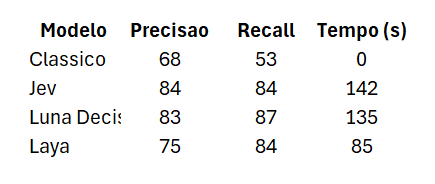